# Figure 3 — development of INTs and of their coupling to the S-A axis (HCP-D)

Age-resolved GAM fits, per parcel and per S-A decile, of rest INTs, task INTs and the task-minus-rest
deflection for one HCP-D task (default: CARIT). Panel A: the fitted rate of change of every parcel across
age, sorted by the S-A axis; B–D: S-A-decile fits and their first and second derivatives; E: the
correlation between the fitted rate of change and the S-A axis across age, with a subject-bootstrap band.
The supplements show the decile fits, the per-stage net change on the S-A axis, and the behavioural analysis.

In [1]:
import os
import warnings
warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import scipy as sp
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

%matplotlib inline

from src.notebook import load_notebook_data
from src.timescales import rest_window_match_for
from src.timescales import (create_ints_dataframe_custom_grouping, convert_data_dict,
                             average_data_dict_converted, compute_deflections,
                             compute_regional_corrs)
from src.plotting import (register_custom_colormaps,
                          figure_scratch_dir, setup_notebook_style, style_ax)
from snaplab_tools.plotting.utils import save_panel
from snaplab_tools.plotting.plotting import plot_correlation, plot_brain_surface_data_single
from patsy import dmatrix
from src.nulls import (null_basis, generate_surrogates, corr_with_null,
                       require_full_parcellation)
from snaplab_tools.gams import detect_change_point, partial_r2_smooth
from src.gams import (fit_all_panels, apply_region_mask, get_series_colors, get_draw_order,
                      compute_deriv_sa_corr, bootstrap_gam_maps,
                      add_sa_decile_colorbar, plot_r_age, deriv_map_spatial_null_p,
                      sa_metric_map, bootstrap_metric_sa_corr, sa_decile_change,
                      SIGNAL_TYPES, signal_labels, signal_units, gam_variant_tags,
                      gam_cache_path, build_nuisance)

setup_notebook_style()

## Panel + analysis support

Helpers for this notebook, gathered so the cells below stay readable. Collapse it.

In [2]:
# ── Panel + analysis support ────────────────────────────────────────────────────────────────
def _draw_stage_boundary(ax, on_image=False):
    _z = None if on_image else 0        # behind the data curves on the line plots
    for _a in boundary_ages:
        ax.axvline(_a, color='0.2', linestyle='--', lw=0.9, alpha=0.9,
                   **({} if _z is None else {'zorder': _z + 0.5}))


# Bold panel label (A, B, ...) at each subplot's top-left corner.
def _panel_label(ax, letter):
    ax.annotate(letter, xy=(0.0, 1.0), xycoords='axes fraction', xytext=(-22, 6),
                textcoords='offset points', fontsize=11, fontweight='bold',
                va='bottom', ha='left', annotation_clip=False)


## Load data

In [3]:
dataset       = 'HCP-D'
n_regions = 400
output_type   = 'timescale_auc_zero_crossing_bp-0.01-0.08hz'
# output_type   = 'timescale_auc_zero_crossing'

# The task this run analyses, set before the load because the length-matched rest depends on it.
task_scan = 'tfMRICARITPA'
# task_scan = 'tfMRIEMOTIONPA'
# task_scan = 'tfMRIGUESSINGPA'

# Rest INTs from full-length runs ('full') or from windows as long as task_scan's run ('matched', chosen by
# rest_window_match_for).
REST_LENGTH   = 'matched'   # 'full' | 'matched'
REST_MATCH    = rest_window_match_for(dataset, task_scan) if REST_LENGTH == 'matched' else None

notebook_data = load_notebook_data(dataset=dataset, output_type=output_type, use_resids=True,
                                   n_regions=n_regions, rest_length=REST_LENGTH, rest_match=REST_MATCH)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-D
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/processed
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       652 subjects

	Initialized Timescales for dataset: HCP-D
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading metric_tsnr: 100%|██████████| 2760/2760 [00:00<00:00, 7341.55it/s]
Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 2760/2760 [00:00<00:00, 7938.95it/s]
Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_restlen-CARIT: 100%|██████████| 2760/2760 [00:00<00:00, 15950.54it/s]


  rest_length='matched' (restlen-CARIT): 1104 rest scans use length-matched windows


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_resids: 100%|██████████| 2760/2760 [00:00<00:00, 8121.86it/s]

Number of subjects: 552


In [4]:
timescales_processor = notebook_data['timescales_processor']
data_dict            = notebook_data['data_dict']
results_dir          = notebook_data['results_dir']
df_neuro             = notebook_data['supporting_data']['df_neuro']
yeo_systems          = notebook_data['supporting_data']['yeo_systems']

sa_axis = df_neuro['SA_Axis'].values
require_full_parcellation(len(yeo_systems), n_regions, 'Yeo-7 system labels')

fig_dir = figure_scratch_dir(dataset)

## Prepare data

In [5]:
timescales_processor.match_registry_to_behavior()
df_behavior = timescales_processor.df_behavior_matched.copy()

rest_scan = 'task-Rest'
# task_scan is set in the config cell at the top: the length-matched rest loaded there depends on it.

data_dict_tsnr      = notebook_data['data_dict_tsnr']
data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)
data_dict_centiles  = convert_data_dict(data_dict, timescales_processor.scan_registry,
                                        brain_map=sa_axis)
data_dict_converted = average_data_dict_converted(data_dict_converted, average_all_rest=True)
data_dict_centiles  = average_data_dict_converted(data_dict_centiles,  average_all_rest=True)
df_tsnr             = create_ints_dataframe_custom_grouping(data_dict_tsnr, average_all_rest=True,
                                                            n_regions=n_regions)

rfMRIREST1PA (552, 400)
rfMRIREST2PA (552, 400)
tfMRICARITPA (552, 400)
tfMRIEMOTIONPA (552, 400)
tfMRIGUESSINGPA (552, 400)
rfMRIREST1PA (552, 10)
rfMRIREST2PA (552, 10)
tfMRICARITPA (552, 10)
tfMRIEMOTIONPA (552, 10)
tfMRIGUESSINGPA (552, 10)


In [6]:
# Summarised rather than displayed: committed notebooks must not carry subject-level behaviour rows (dataset data-use terms).
print(f'df_behavior: {df_behavior.shape[0]} subjects x {df_behavior.shape[1]} columns')
print(', '.join(map(str, df_behavior.columns)))

df_behavior: 552 subjects x 45 columns
sex, age, meanFD, nih_fluidcogcomp_unadjusted, nih_crycogcomp_unadjusted, nih_dccs_ageadjusted, nih_flanker_ageadjusted, tbx_ls, tbx_reading_score, tbx_vocab_theta, nih_patterncomp_ageadjusted, er40_c_cr, er40_c_ang, er40_c_fear, er40_c_hap, er40_c_sad, cbcl_attention_raw, cbcl_aggressive_raw, cbcl_internal_raw, cbcl_external_raw, cbcl_total_raw, cbcl_anxiety_raw, ysr_internal, ysr_external, ysr_total, bissc_total, bas_drive, bas_fs, bas_rr, premed_score, senseek_score, persev_score, pss_tscore, fearanx_tscore, life_satisfaction_tscore, carit_nogo_acc, carit_omission_rate, carit_dprime, carit_criterion, carit_nonresponder, carit_fa_rate_win, carit_fa_rate_lose, carit_perf_exclude, carit_n_go_trials, carit_n_nogo_trials


## Fit GAMs

In [7]:
# ── GAM + bootstrap configuration ────────────────────────────────
# fit_recipe is 'historical' (n_splines=4, fixed lam=0.1, the original cache file) or 'gcv' (n_splines=5, lam
# chosen per region by GCV).
fit_recipe = 'gcv'

# absolute=True defines the deflection as |task - rest| and False as signed task - rest.
absolute            = True
# Demeaning: if True, every series (region / decile) is centred on its own mean before its GAM is fit.
demean              = True

# fit_recipe + absolute + demean + REST_LENGTH (+ REST_MATCH) are the run's identity.
_tags        = gam_variant_tags(fit_recipe, absolute, demean, rest_length=REST_LENGTH,
                                rest_match=REST_MATCH)
n_splines    = _tags['n_splines']
lam          = _tags['lam']
recipe_tag   = _tags['recipe_tag']
absolute_tag = _tags['absolute_tag']
demean_tag   = _tags['demean_tag']
_absolute_cfg, _demean_cfg, _rest_length_cfg, _rest_match_cfg = absolute, demean, REST_LENGTH, REST_MATCH   # snapshots for the cache-vs-config check below

# ── How panel E judges significance ──────────────────────────────
# SIG_METHOD judges panel E by subject bootstrap, spatial null or both (bootstrap band with spatial marks),
# but keep 'bootstrap' while the exported spatial-null p is all-NaN.
SIG_METHOD     = 'bootstrap'        # 'bootstrap' | 'spatial' | 'both'
SA_CORR_METHOD = 'pearson'     # correlation for the derivative x S-A coupling ('pearson'/'spearman')
N_PERMS        = 10000         # BrainSMASH surrogates of the S-A axis. Match fig4's N_PERMS and
                               # the cached 'sa_axis' nulls are shared rather than regenerated.
SIG_ALPHA      = 0.05          # threshold on the spatial-null p
if SIG_METHOD not in ('bootstrap', 'spatial', 'both'):
    raise ValueError(f"SIG_METHOD must be 'bootstrap', 'spatial' or 'both'; got {SIG_METHOD!r}")
# N_BOOT is the one bootstrap count here (panel E's band, the stage maps and the stage supplement), and
# changing it needs FORCE_RERUN = True.
N_BOOT              = 5000      # subject bootstrap resamples
boot_seed           = 42        # resampling seed (shared by all bootstrap reductions)
N_JOBS              = -1        # joblib workers for the bootstrap (-1 = all cores)

# The stage boundary is detected on deriv1
stage_boundary_signal   = 'deriv1'       # drives the exported stage maps ('deriv1'|'deriv2'|'pred')
boundary_report_signals = ('deriv2', 'pred')    # extra signals to report a boundary CI for (maps unaffected)

# n_bkps sets how many change points the figure marks, without changing the two-stage maps exported for fig4.
n_bkps = 1

# The GAM fits and bootstrap are cached, so set FORCE_RERUN = True after changing the recipe, absolute, demean
# or the stage-boundary definition.
FORCE_RERUN    = False
gam_out_dir    = os.path.join(timescales_processor.output_dir, 'results', dataset, 'gam')
os.makedirs(gam_out_dir, exist_ok=True)
gam_cache_file = gam_cache_path(gam_out_dir, dataset, n_regions, task_scan, _tags)

# Shared spatial-null basis (same call fig4 makes, so both notebooks hit the same cache).
distance_matrix, hemi_labels, cache_dir = null_basis(timescales_processor, dataset, n_regions)
print(f'GAM cache -> {os.path.basename(gam_cache_file)}')
print(f'Panel E significance: {SIG_METHOD} ({SA_CORR_METHOD}); surrogate cache {cache_dir}')

GAM cache -> HCP-D_400_tfMRICARITPA_ns5-gcv_abs_demean_restlen-CARIT_regional_gam_results.npy
Panel E significance: bootstrap (pearson); surrogate cache /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales/results/HCP-D/brainsmash_nulls


In [8]:
# Load the cached GAM and bootstrap outputs, or compute and save them (SIGNAL_TYPES names the INT signal,
# unlike snaplab_tools.gams.SIGNALS).
SIGNALS = SIGNAL_TYPES

if (not FORCE_RERUN) and os.path.exists(gam_cache_file):
    save_dict = np.load(gam_cache_file, allow_pickle=True).item()
    print(f'Loaded cached GAM + bootstrap outputs <- {gam_cache_file}')
    print('  (set FORCE_RERUN = True in the config cell above to recompute and overwrite)')
else:
    # ===== Region- and decile-level data =====
    rest_full = data_dict_converted[rest_scan]
    try:
        task_full = data_dict_converted[task_scan]
    except (KeyError, TypeError):
        task_full = data_dict_converted[rest_scan]
    n_subs = task_full.shape[0]
    n_regions = task_full.shape[1]

    # Covariate data (age smooth + nuisance: sex, head motion, each subject's mean rest INT).
    # build_nuisance is shared with fig4, whose bootstrap has to reproduce this exact fit.
    age = df_behavior['age'].values
    nuisance = build_nuisance(df_behavior, rest_full, dataset)
    age_grid = np.linspace(age.min(), age.max(), 200)

    deflection_full = compute_deflections(rest_full, task_full, absolute=absolute)

    rest_dec = data_dict_centiles[rest_scan]
    try:
        task_dec = data_dict_centiles[task_scan]
    except (KeyError, TypeError):
        task_dec = data_dict_centiles[rest_scan]
    deflection_dec = compute_deflections(rest_dec, task_dec, absolute=absolute)
    n_deciles = rest_dec.shape[1]

    # ===== Fit GAMs (decile + region). lam is a float (fixed) or 'gcv' (per-series grid search).
    # demean comes from the config cell and is used identically here, in the bootstrap, and in the
    # partial R^2 below (partial_r2_smooth requires the same flag the fits used). =====
    results_dec = fit_all_panels(age, rest_dec, task_dec, deflection_dec, age_grid,
                                 n_splines=n_splines, lam=lam, demean=demean, show_ci=False,
                                 nuisance=nuisance)

    apply_tsnr_mask = False  # set True to exclude low-tSNR regions
    if apply_tsnr_mask:
        region_mask = (df_tsnr[task_scan] < np.quantile(df_tsnr[task_scan], q=0.1)).values
    else:
        region_mask = None
    rest_reg, task_reg, defl_reg, sa_axis_reg = apply_region_mask(
        region_mask, rest_full, task_full, deflection_full, sa_axis=sa_axis)
    results_reg = fit_all_panels(age, rest_reg, task_reg, defl_reg, age_grid,
                                 n_splines=n_splines, lam=lam, demean=demean, show_ci=False,
                                 nuisance=nuisance)
    reg_data = {'rest': rest_reg, 'task': task_reg, 'deflection': defl_reg}
    print(f'GAMs fit ({fit_recipe}, absolute={absolute}, demean={demean}). '
          f'Decile {deflection_dec.shape} | '
          f'Regional {defl_reg.shape} | Nuisance {None if nuisance is None else nuisance.shape}')
    if lam == 'gcv':
        _ed = np.array([g.statistics_['edof'] for g in results_reg['deflection']['gams'] if g is not None])
        _lam_med = np.nanmedian(results_reg['deflection']['lams'])
        print(f'  GCV lam median {_lam_med:.2f} | regional edof median {np.median(_ed):.2f} '
              f'(incl. nuisance terms)')

    # Bootstrap all three signals over the same resamples (boot_seed), reducing each to panel E's curve and, for the deflection, the stage maps and boundary.
    _boundary_signals = (stage_boundary_signal,) + tuple(boundary_report_signals)
    boot_curves, r_ci_lo, r_ci_hi = {}, {}, {}
    for sig in SIGNALS:
        _is_defl = sig == 'deflection'
        # Freeze this signal's per-region smoothing from its own full-sample fit (the GCV-selected
        # lam, or the fixed scalar) so every resample reuses it rather than re-selecting it.
        _lam = results_reg[sig]['lams']
        _boot = bootstrap_gam_maps(
            reg_data[sig], age, age_grid, sa_axis_vals=sa_axis_reg,
            inflection_age=stage_boundary_signal if _is_defl else None,
            report_boundary_signals=boundary_report_signals if _is_defl else (),
            n_splines=n_splines, lam=_lam, demean=demean, nuisance=nuisance, annualized=True,
            n_boot=N_BOOT, method='pearson', random_state=boot_seed, n_jobs=N_JOBS)
        boot_curves[sig] = _boot['sa_curves']
        r_ci_lo[sig] = np.nanpercentile(boot_curves[sig], 2.5,  axis=0)
        r_ci_hi[sig] = np.nanpercentile(boot_curves[sig], 97.5, axis=0)
        if _is_defl:
            frozen_lam = _lam                                        # exported for fig4
            boot_stage1, boot_stage2 = _boot['stage1'], _boot['stage2']
            boot_boundary = {s: _boot[f'boundary_{s}'] for s in _boundary_signals}

    # The full-sample deflection boundary marks every panel and defines fig4's stages, with its CI from the bootstrap above.
    boundary_pt    = {s: detect_change_point(results_reg['deflection']['pred'], age_grid, signal=s)
                      for s in _boundary_signals}
    inflection_age = float(boundary_pt[stage_boundary_signal]['location'])
    # Draw n_bkps boundaries (n_bkps = 1 reproduces the single stage boundary), detected on the same signal as
    # the maps.
    boundary_ages  = detect_change_point(results_reg['deflection']['pred'], age_grid,
                                           signal=stage_boundary_signal, n_bkps=n_bkps)['locations']
    # Each signal's OWN boundary (point estimate only, same detector). fig4 can partition rest/task
    # by these instead of the shared deflection boundary; 'deflection' here equals inflection_age.
    signal_inflection = {sig: float(detect_change_point(results_reg[sig]['pred'], age_grid,
                                                        signal=stage_boundary_signal)['location'])
                         for sig in SIGNALS}

    # Spatial null for panel E: surrogate the S-A axis with the fit held fixed, complementing the subject bootstrap.
    require_full_parcellation(
        sa_axis_reg.shape[0], n_regions, 'the regional fit',
        'The S-A axis surrogates span the whole parcellation, so set apply_tsnr_mask = False.')
    sa_axis_surr = generate_surrogates(
        sa_axis_reg, name='SA_Axis', n_regions=n_regions, n_perms=N_PERMS,
        distance_matrix=distance_matrix, hemi=hemi_labels, cache_dir=cache_dir, seed=0)
    sa_null_p = {}
    for sig in SIGNALS:
        _r_chk, sa_null_p[sig] = deriv_map_spatial_null_p(
            results_reg[sig]['deriv'], sa_axis_reg, sa_axis_surr, method=SA_CORR_METHOD)
        # The null's r can differ slightly from the plotted curve because it keeps only parcels finite
        # everywhere, so report the gap.
        _gap = np.nanmax(np.abs(_r_chk - compute_deriv_sa_corr(
            results_reg[sig]['deriv'], sa_axis_reg, method=SA_CORR_METHOD)))
        print(f'  spatial null [{sig}]: {int((sa_null_p[sig] < SIG_ALPHA).sum())}/'
              f'{len(age_grid)} age points p<{SIG_ALPHA} (max |r| gap vs plotted curve {_gap:.2e})')

    print(f'Bootstrap done ({N_BOOT} iters × {len(SIGNALS)} signals, n_jobs={N_JOBS}). '
          '95% CI at age midpoint:')
    for sig in SIGNALS:
        print(f'  {sig:<11}[{r_ci_lo[sig][100]:.3f}, {r_ci_hi[sig][100]:.3f}]  '
              f'own boundary {signal_inflection[sig]:.2f} yr')
    _b = boot_boundary[stage_boundary_signal]
    print(f'Data-driven stage boundary [{stage_boundary_signal}]: {inflection_age:.2f} yr '
          f'(point est.), 95% CI [{np.nanpercentile(_b, 2.5):.2f}, {np.nanpercentile(_b, 97.5):.2f}] yr.')
    if n_bkps > 1:
        print(f'  n_bkps={n_bkps} boundaries (annotation only): {[round(a, 2) for a in boundary_ages]} yr')
    for s in boundary_report_signals:
        _bs = boot_boundary[s]
        print(f'  boundary [{s}] (robustness): {boundary_pt[s]["location"]:.2f} yr (point est.), '
              f'95% CI [{np.nanpercentile(_bs, 2.5):.2f}, {np.nanpercentile(_bs, 97.5):.2f}] yr.')
    print(f'Bootstrap stage maps for fig4: stage1 {boot_stage1.shape}, stage2 {boot_stage2.shape}.')

    # ===== Assemble outputs (figure inputs + cross-notebook export for fig4) =====
    save_dict = {
        'age_grid':    age_grid,
        'sa_axis_reg': sa_axis_reg,
        'task_scan':   task_scan,
        'n_deciles':   n_deciles,
    }
    for sig in SIGNALS:
        save_dict[f'{sig}_deriv']     = results_reg[sig]['deriv']
        save_dict[f'{sig}_pred']      = results_reg[sig]['pred']
        save_dict[f'{sig}_deriv_dec'] = results_dec[sig]['deriv']
        save_dict[f'{sig}_pred_dec']  = results_dec[sig]['pred']
        save_dict[f'{sig}_partial_r2'] = partial_r2_smooth(
            reg_data[sig], age, results_reg[sig]['gams'], nuisance=nuisance, demean=demean
        )
        # Panel E inputs, per signal: observed r curve + its own bootstrap band.
        save_dict[f'{sig}_r_vals']      = compute_deriv_sa_corr(
            results_reg[sig]['deriv'], sa_axis_reg, method='pearson')
        save_dict[f'{sig}_boot_curves'] = boot_curves[sig]
        save_dict[f'{sig}_r_ci_lo']     = r_ci_lo[sig]
        save_dict[f'{sig}_r_ci_hi']     = r_ci_hi[sig]
        save_dict[f'{sig}_sa_null_p']   = sa_null_p[sig]   # pointwise BrainSMASH p per age
        # fig4 inputs, per signal: the subject × region matrix it re-fits per bootstrap resample,
        # the frozen smoothing for those refits, and this signal's own stage boundary.
        save_dict[f'{sig}_reg']            = reg_data[sig]
        save_dict[f'{sig}_lams']           = results_reg[sig]['lams']
        save_dict[f'{sig}_inflection_age'] = signal_inflection[sig]
    save_dict['boot_stage1']    = boot_stage1     # (n_boot, n_regions) fig4 enrichment bootstrap
    save_dict['boot_stage2']    = boot_stage2
    save_dict['inflection_age'] = inflection_age  # deflection boundary (yr); fig4's default partition
    save_dict['stage_boundary_signal'] = stage_boundary_signal
    save_dict['boundary_ages']  = boundary_ages   # n_bkps annotation boundaries (yr)
    save_dict['n_bkps']         = n_bkps
    for s in _boundary_signals:
        save_dict[f'boundary_{s}']    = boot_boundary[s]                       # (n_boot,) boundary CI
        save_dict[f'boundary_pt_{s}'] = float(boundary_pt[s]['location'])  # full-sample point est.
    save_dict['n_boot']         = N_BOOT
    save_dict['n_perms']        = N_PERMS                                      # spatial-null count
    save_dict['sa_corr_method'] = SA_CORR_METHOD
    save_dict['boot_seed']      = boot_seed
    save_dict['fit_recipe']     = fit_recipe                                   # provenance
    save_dict['n_splines']      = n_splines
    save_dict['demean']         = demean                                       # centring used by every fit here
    save_dict['absolute']       = absolute                                     # |task-rest| vs signed (task-rest)
    save_dict['rest_length']    = REST_LENGTH                                  # rest INTs: full runs or length-matched windows
    save_dict['rest_match']     = REST_MATCH                                   # the task those windows match (None when full)
    # Record whether a tSNR mask was applied, because fig4 needs the full parcellation and refuses a masked
    # export.
    save_dict['region_mask_applied'] = region_mask is not None
    save_dict['gam_lam']        = lam if isinstance(lam, str) else float(lam)
    save_dict['frozen_lam']     = frozen_lam                                   # (n_regions,) deflection smoothing used
    save_dict['rest_reg']    = rest_reg
    save_dict['sa_axis']     = sa_axis
    save_dict['df_behavior'] = df_behavior

    np.save(gam_cache_file, save_dict)
    print(f'Computed and saved GAM + bootstrap outputs -> {gam_cache_file}')
    for sig in SIGNALS:
        r2 = save_dict[f'{sig}_partial_r2']
        print(f"  {sig}_partial_r2: shape={r2.shape}, mean={np.nanmean(r2):.4f}, max={np.nanmax(r2):.4f}")

Loaded cached GAM + bootstrap outputs <- /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales/results/HCP-D/gam/HCP-D_400_tfMRICARITPA_ns5-gcv_abs_demean_restlen-CARIT_regional_gam_results.npy
  (set FORCE_RERUN = True in the config cell above to recompute and overwrite)


In [9]:
# Reconstruct the figure inputs from save_dict (identical whether loaded or freshly computed).
age_grid    = save_dict['age_grid']
sa_axis_reg = save_dict['sa_axis_reg']
n_deciles   = save_dict['n_deciles']

# Panel E inputs per signal, None for rest/task in old caches (which then draw a bare curve).
r_ci_lo   = {sig: save_dict.get(f'{sig}_r_ci_lo') for sig in SIGNALS}
r_ci_hi   = {sig: save_dict.get(f'{sig}_r_ci_hi') for sig in SIGNALS}
sa_null_p = {sig: save_dict.get(f'{sig}_sa_null_p') for sig in SIGNALS}
# Plot with the options the cache was built with, warning when the config cell disagrees.
demean      = bool(save_dict.get('demean', True))
absolute    = bool(save_dict.get('absolute', True))
rest_length = str(save_dict.get('rest_length', 'full'))    # exports predating the key are full-length
rest_match  = save_dict.get('rest_match')                  # the matched task; None when full-length
_tags_cache = gam_variant_tags(save_dict.get('fit_recipe', fit_recipe), absolute, demean,
                               rest_length=rest_length, rest_match=rest_match)
variant_tag = _tags_cache['variant_tag']
for _name, _cached, _cfg in [('demean', demean, _demean_cfg), ('absolute', absolute, _absolute_cfg),
                             ('rest_length', rest_length, _rest_length_cfg),
                             ('rest_match', rest_match, _rest_match_cfg)]:
    if _cached != _cfg:
        print(f'WARNING: cache was built with {_name}={_cached} but the config cell says '
              f'{_name}={_cfg}. Set FORCE_RERUN = True to rebuild.')

# The deflection-derived stage boundary (point estimate and bootstrap CI), a fixed reference on every panel.
boundary_signal = save_dict.get('stage_boundary_signal', 'deriv1')
boundary_pt_age = save_dict.get('inflection_age')                  # float, data-driven point estimate (yr)
_bd             = save_dict.get(f'boundary_{boundary_signal}')     # (n_boot,) or None
boundary_ci     = np.nanpercentile(_bd, [2.5, 97.5]) if _bd is not None else None
# n_bkps change-point boundaries drawn as vertical lines (falls back to the single boundary)
boundary_ages   = save_dict.get('boundary_ages',
                                [boundary_pt_age] if boundary_pt_age is not None else [])

results_reg = {sig: {'deriv': save_dict[f'{sig}_deriv'],     'pred': save_dict[f'{sig}_pred']}
               for sig in SIGNALS}
results_dec = {sig: {'deriv': save_dict[f'{sig}_deriv_dec'], 'pred': save_dict[f'{sig}_pred_dec']}
               for sig in SIGNALS}

cmap          = register_custom_colormaps()['snap_sydnor_sa']   # registers all custom maps; sydnor_sa colours the decile lines + S-A colorbar
series_colors = get_series_colors('decile', n_deciles, cmap)
draw_order    = get_draw_order('decile', n_deciles)

## Figure 3

Panel E [deflection]: significance from bootstrap CI; 98/200 age points marked.
-> fig3_combined_tfMRICARITPA_deflection_abs_demean_restlen-CARIT_bootstrap.{png,svg}


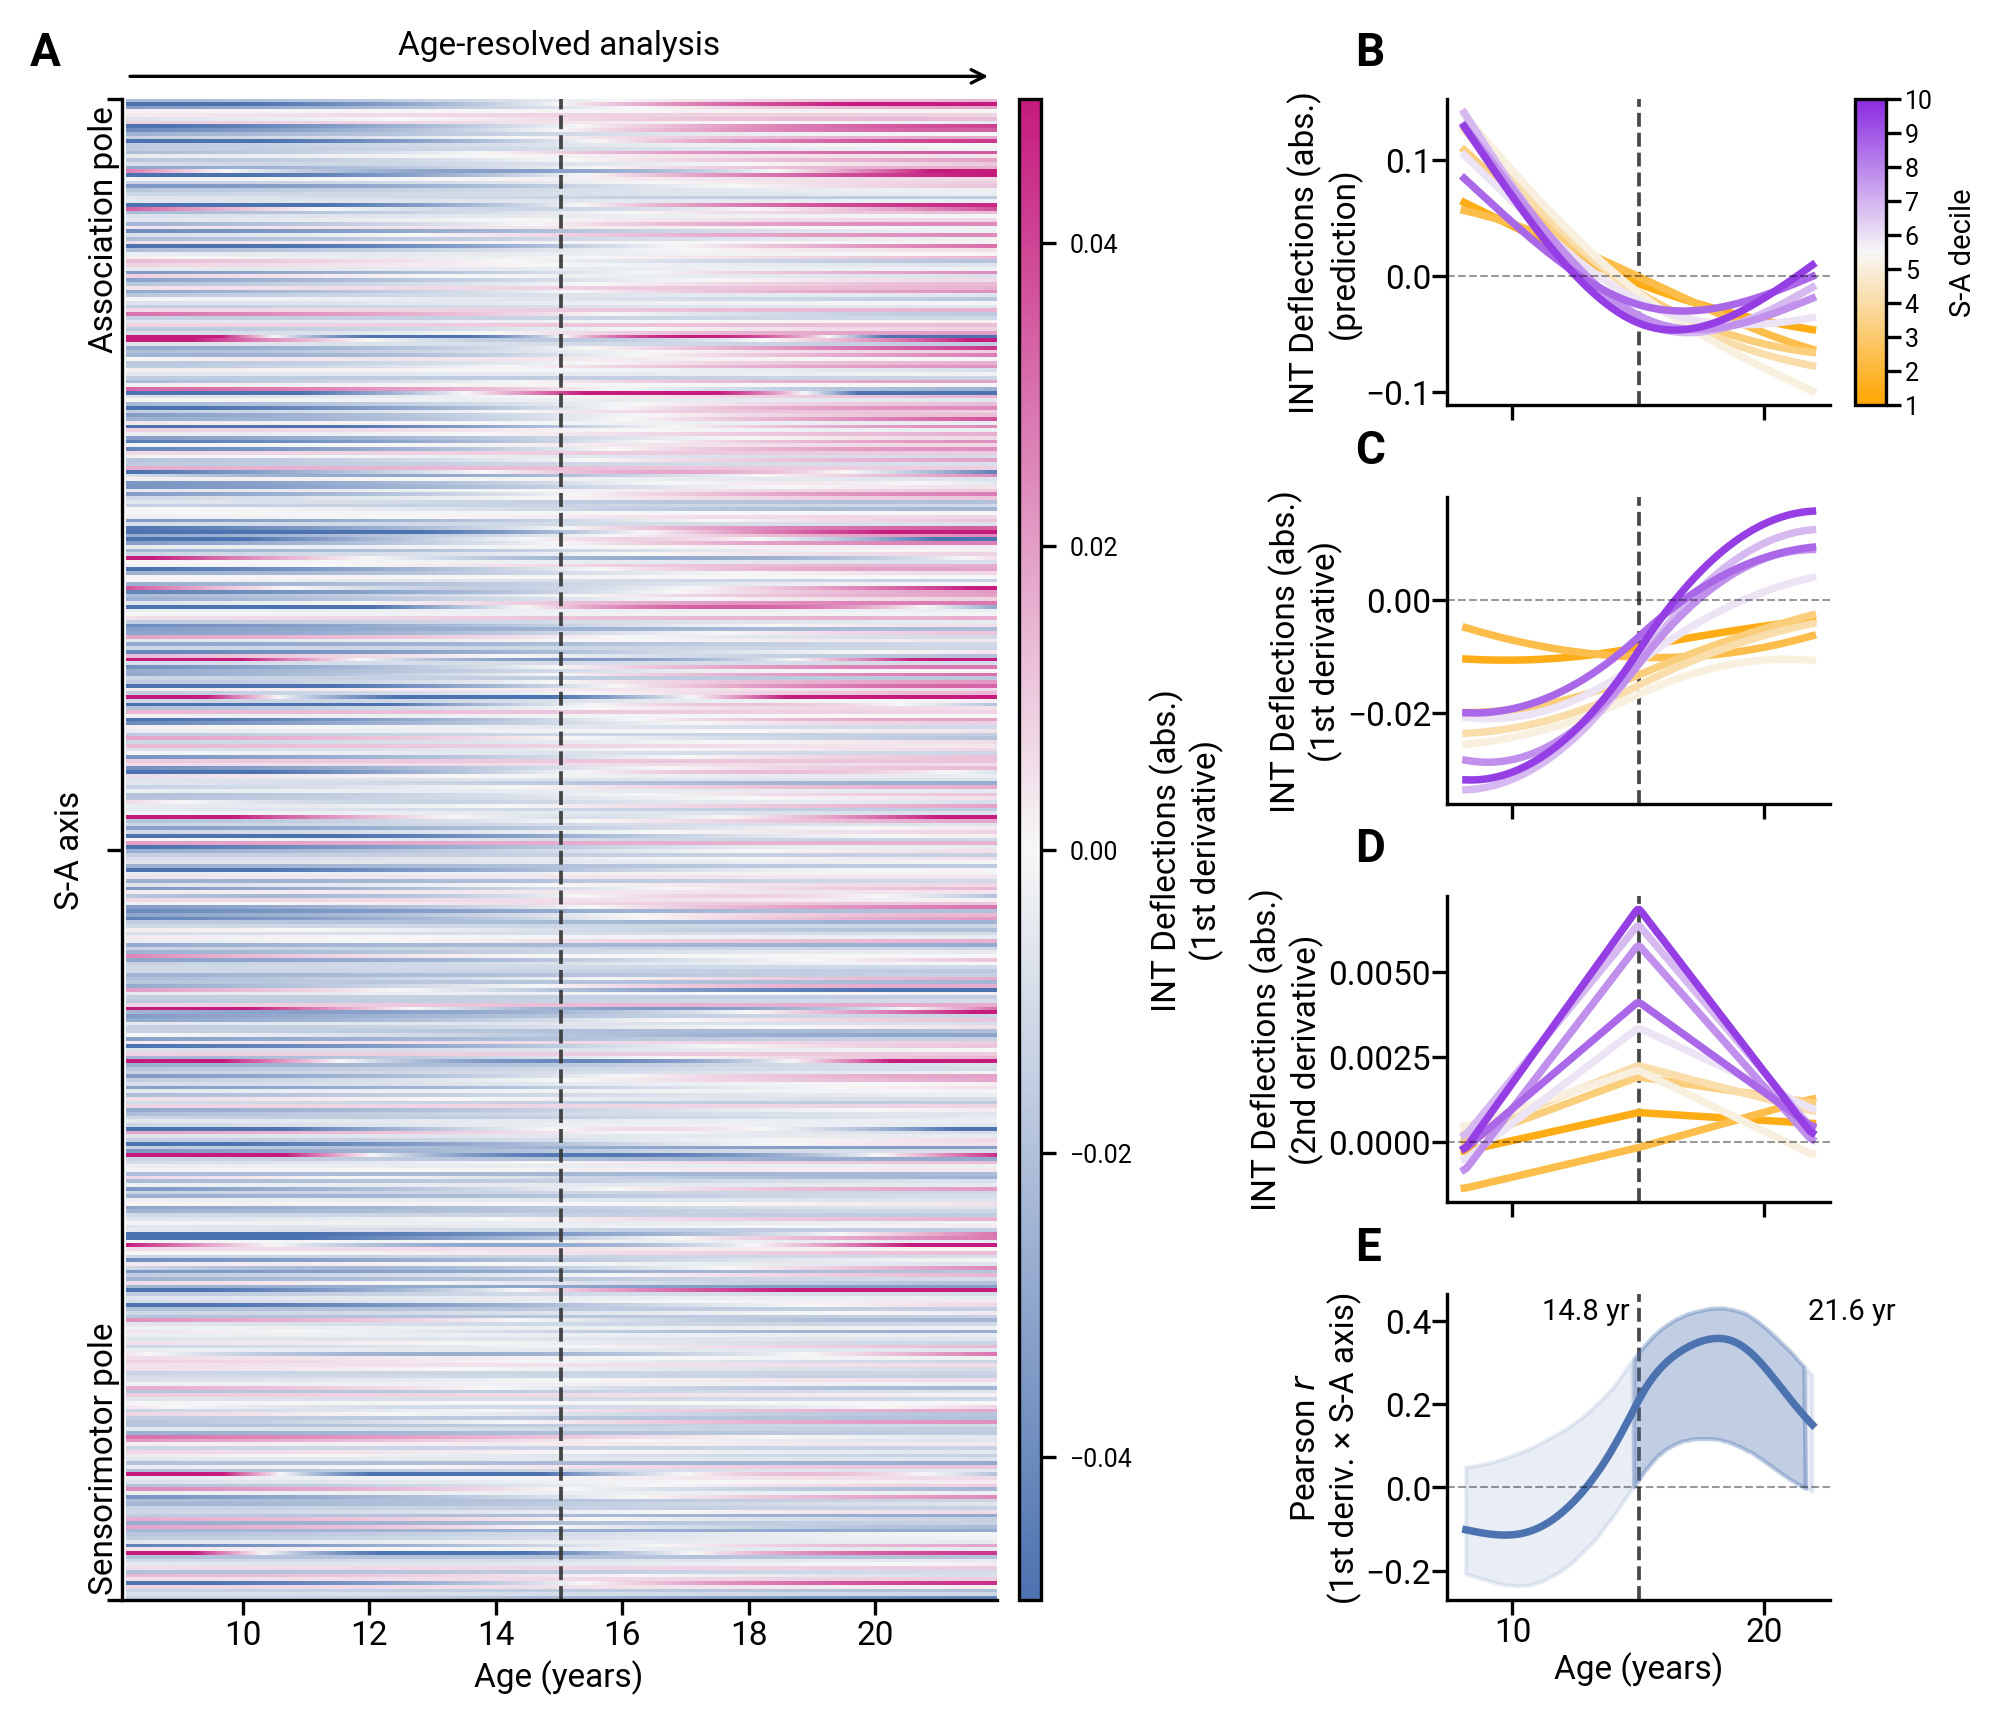

In [10]:
# --- Parameters ---
# for signal_type in ['rest', 'task', 'deflection']:
signal_type = 'deflection'  # 'rest', 'task', or 'deflection'
plot_level  = 'region'      # 'region' or 'decile'
heatmap_cmap = 'snap_blue_pink'  # diverging map for panel A, clear of the S-A axis colours (see snaplab_tools.plotting.utils.show_colormaps())
# ------------------

_signal_labels = signal_labels(absolute)   # shared with fig4 so the two cannot drift
lw = 1.8

# Heatmap data
_reg_deriv = results_reg[signal_type]['deriv']

if plot_level == 'region':
    sort_idx     = np.argsort(sa_axis_reg)
    deriv_sorted = _reg_deriv[sort_idx]
    ylabel       = 'S-A axis'
    bottom_label = 'Sensorimotor pole'
    top_label    = 'Association pole'
else:
    deriv_sorted = results_dec[signal_type]['deriv']
    ylabel       = 'S-A axis decile'
    bottom_label = 'Sensorimotor'
    top_label    = 'Association'

n_rows = deriv_sorted.shape[0]
vmax   = np.nanpercentile(np.abs(deriv_sorted), 98)

# Panel E: observed r curve plus whichever significance verdict SIG_METHOD asks for -- both are
# per signal, because a band or a p-curve borrowed from another signal silently mislabels the
# shading and the crossing-age annotations.
r_vals = compute_deriv_sa_corr(_reg_deriv, sa_axis_reg, method=SA_CORR_METHOD)
_ci_lo, _ci_hi = r_ci_lo[signal_type], r_ci_hi[signal_type]
_null_p        = sa_null_p[signal_type]
_have_ci, _have_p = _ci_lo is not None, _null_p is not None
if SIG_METHOD in ('bootstrap', 'both') and not _have_ci:
    print(f'NOTE: no bootstrap CI cached for {signal_type!r}; falling back to a bare curve.')
if SIG_METHOD in ('spatial', 'both') and not _have_p:
    print(f'NOTE: no spatial-null p cached for {signal_type!r} (regenerate with '
        'FORCE_RERUN = True); falling back to the bootstrap verdict.')

# SA-decile 2nd derivative (acceleration) of the fit: central differences of pred with
# edge_order=2 (matches build_signal). edge_order=2 avoids the compounded boundary
# artifact a plain double np.gradient produces at the age extremes.
_pred_dec   = results_dec[signal_type]['pred']
_deriv2_dec = np.gradient(np.gradient(_pred_dec, age_grid, axis=1, edge_order=2),
                        age_grid, axis=1, edge_order=2)

# Figure layout
fig      = plt.figure(figsize=(8.5, 6.5), dpi=300)
gs_outer = GridSpec(1, 2, figure=fig, width_ratios=[1, 1], wspace=0.15)

# Left column: heatmap | narrow vertical colorbar
gs_left   = GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[0],
                                    width_ratios=[1, 0.025], wspace=0.05)
ax_heat   = fig.add_subplot(gs_left[0])
ax_cbar_h = fig.add_subplot(gs_left[1])

# Right column: pred / deriv1 / deriv2 / Pearson r (4 panels; SA-decile colorbar added as overlay)
gs_right = GridSpecFromSubplotSpec(4, 1, subplot_spec=gs_outer[1],
                                height_ratios=[1, 1, 1, 1], hspace=0.3)
ax0 = fig.add_subplot(gs_right[0])
ax1 = fig.add_subplot(gs_right[1], sharex=ax0)
ax2 = fig.add_subplot(gs_right[2], sharex=ax0)
ax3 = fig.add_subplot(gs_right[3], sharex=ax0)

# Heatmap
im = ax_heat.imshow(
    deriv_sorted, aspect='auto', origin='lower',
    extent=[age_grid[0], age_grid[-1], 0, n_rows],
    cmap=heatmap_cmap, vmin=-vmax, vmax=vmax, interpolation='nearest',
)
_draw_stage_boundary(ax_heat, on_image=True)

ax_heat.set_xlabel('Age (years)', fontsize=8, labelpad=2)
ax_heat.set_ylabel(ylabel, fontsize=8, labelpad=4)
if plot_level == 'region':
    ax_heat.set_yticks([0, n_rows // 2, n_rows])
    ax_heat.set_yticklabels(['', '', ''], fontsize=8)
else:
    ax_heat.set_yticks(np.arange(n_rows) + 0.5)
    ax_heat.set_yticklabels([str(i + 1) for i in range(n_rows)], fontsize=8)
ax_heat.tick_params(labelsize=8, pad=1)

ax_heat.annotate(top_label,    xy=(age_grid[0], n_rows), xytext=(-8, -1.5), rotation=90,
                textcoords='offset points', fontsize=8, va='top',    annotation_clip=False)
ax_heat.annotate(bottom_label, xy=(age_grid[0], 0),      xytext=(-8,  1.5), rotation=90,
                textcoords='offset points', fontsize=8, va='bottom', annotation_clip=False)
ax_heat.annotate('', xy=(age_grid[-1], n_rows + n_rows * 0.015),
                xytext=(age_grid[0],  n_rows + n_rows * 0.015),
                arrowprops=dict(arrowstyle='->', color='k', lw=0.8), annotation_clip=False)
ax_heat.text((age_grid[0] + age_grid[-1]) / 2, n_rows + n_rows * 0.025,
            'Age-resolved analysis', ha='center', va='bottom', fontsize=8, clip_on=False)

cb_h = fig.colorbar(im, cax=ax_cbar_h, orientation='vertical')
cb_h.set_label(f'{_signal_labels[signal_type]}\n(1st derivative)', fontsize=8)
cb_h.ax.yaxis.set_label_position('right')
cb_h.ax.tick_params(labelsize=6)

# Line plots: pred (ax0), 1st derivative (ax1), 2nd derivative (ax2). style_ax(demean=...) only
# controls the dashed y=0 reference line: meaningful for the demeaned prediction panel, and always
# meaningful for the derivative panels (zero rate / zero acceleration), so those keep it on.
for i in draw_order:
    ax0.plot(age_grid, results_dec[signal_type]['pred'][i], color=series_colors[i], lw=lw)
style_ax(ax0, 'Age (years)', f'{_signal_labels[signal_type]}\n(prediction)', None, demean=demean)
ax0.set_xlabel('')
ax0.set_box_aspect(0.8)
plt.setp(ax0.get_xticklabels(), visible=False)

for i in draw_order:
    ax1.plot(age_grid, results_dec[signal_type]['deriv'][i], color=series_colors[i], lw=lw)
style_ax(ax1, 'Age (years)', f'{_signal_labels[signal_type]}\n(1st derivative)', None, demean=True)
ax1.set_xlabel('')
ax1.set_box_aspect(0.8)
plt.setp(ax1.get_xticklabels(), visible=False)

for i in draw_order:
    ax2.plot(age_grid, _deriv2_dec[i], color=series_colors[i], lw=lw)
style_ax(ax2, 'Age (years)', f'{_signal_labels[signal_type]}\n(2nd derivative)', None, demean=True)
ax2.set_xlabel('')
ax2.set_box_aspect(0.8)
plt.setp(ax2.get_xticklabels(), visible=False)

# Panel E: the band is the subject bootstrap and the significance marks follow SIG_METHOD.
_band = (_ci_lo, _ci_hi) if (_have_ci and SIG_METHOD in ('bootstrap', 'both')) else None
_sig  = (_null_p < SIG_ALPHA) if (_have_p and SIG_METHOD in ('spatial', 'both')) else None
_sig_used = plot_r_age(ax3, age_grid, r_vals, ci=_band, sig=_sig,
                    style='band' if _band is not None else 'trace', lw=lw)
_src = ('spatial null' if _sig is not None else
        'bootstrap CI' if _band is not None else 'none')
print(f'Panel E [{signal_type}]: significance from {_src}; '
    f'{int(_sig_used.sum())}/{len(age_grid)} age points marked.')
ax3.set_xlabel('Age (years)', fontsize=8, labelpad=1)
ax3.set_ylabel('Pearson $r$\n(1st deriv. × S-A axis)', fontsize=8, labelpad=1)
ax3.tick_params(labelsize=8, pad=0.25)
ax3.set_box_aspect(0.8)
ax3.spines[['top', 'right']].set_visible(False)

# tau line(s) on the right-column panels (matching the heatmap)
for _ax in (ax0, ax1, ax2, ax3):
    _draw_stage_boundary(_ax)

# Bold panel labels: A = heatmap, B-E = right column (top -> bottom)
for _ax, _lab in [(ax_heat, 'A'), (ax0, 'B'), (ax1, 'C'), (ax2, 'D'), (ax3, 'E')]:
    _panel_label(_ax, _lab)

# SA-decile colorbar on the right-hand side of the top-right panel (ax0)
fig.canvas.draw()
add_sa_decile_colorbar(fig, ax0, cmap, n_deciles, orientation='vertical')

# dpi=1000: panel A is a 400-row imshow, which needs more than the 300 dpi a line panel wants.
_path = save_panel(fig, fig_dir,
                f'fig3_combined_{task_scan}_{signal_type}{variant_tag}_{SIG_METHOD}',
                dpi=1000)
print(f'-> {os.path.basename(_path)}.{{png,svg}}')
plt.show()

## Figure 3 — supplement: S-A decile GAM fits

S-A decile GAM fits [deflection, 10 deciles] -> fig3_supp_decile_pred_tfMRICARITPA_deflection_abs_demean_restlen-CARIT.{png,svg}


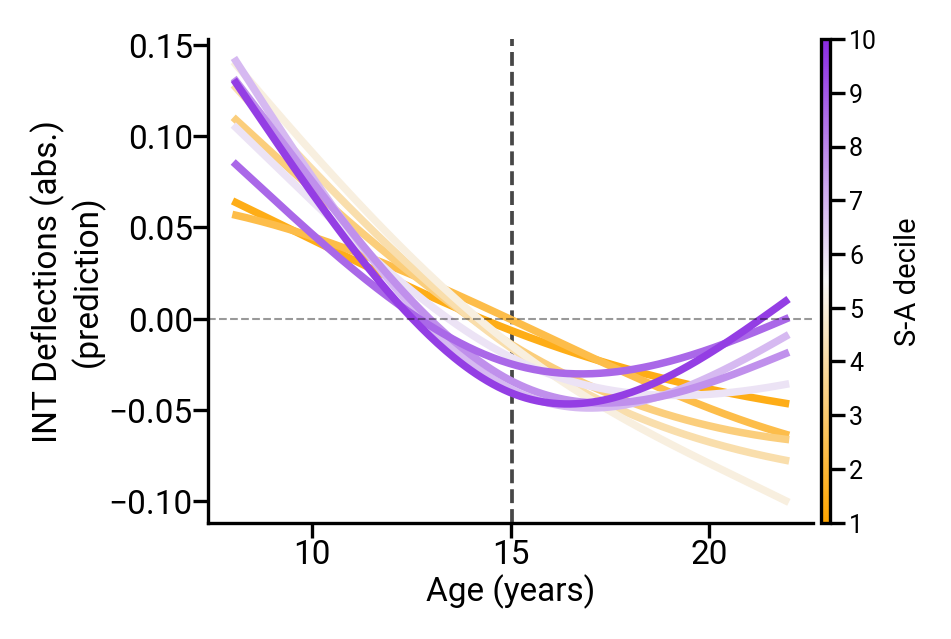

In [11]:
# ── Supplementary: panel B on its own ────────────────────────────────────────────────────────────
# Panel B on its own, drawn from the same cached decile fits and following signal_type from the figure cell.
SUPP_PRED_FIGSIZE = (2.6, 2.2)     # inches (the axes; the colorbar is placed outside it)

fig, ax = plt.subplots(figsize=SUPP_PRED_FIGSIZE, dpi=300)
for i in draw_order:
    ax.plot(age_grid, results_dec[signal_type]['pred'][i], color=series_colors[i], lw=lw)
_draw_stage_boundary(ax)
# demean=demean: style_ax's dashed y=0 line only means something when the fits were centred.
style_ax(ax, 'Age (years)', f'{_signal_labels[signal_type]}\n(prediction)', None, demean=demean)
ax.set_box_aspect(0.8)

# The same S-A decile colorbar the main figure hangs off panel B. add_sa_decile_colorbar aligns to
# the axes' final position, so the draw() first is required, not decorative.
fig.canvas.draw()
add_sa_decile_colorbar(fig, ax, cmap, n_deciles, orientation='vertical')

_path = save_panel(fig, fig_dir,
                   f'fig3_supp_decile_pred_{task_scan}_{signal_type}{variant_tag}')
print(f'S-A decile GAM fits [{signal_type}, {n_deciles} deciles] '
      f'-> {os.path.basename(_path)}.{{png,svg}}')
plt.show()

## Figure 3 — supplement: per-decile GAM fit check

10 deciles on a 2x5 grid -> fig3_supp_decile_fits_tfMRICARITPA_deflection_abs_demean_restlen-CARIT.{png,svg}


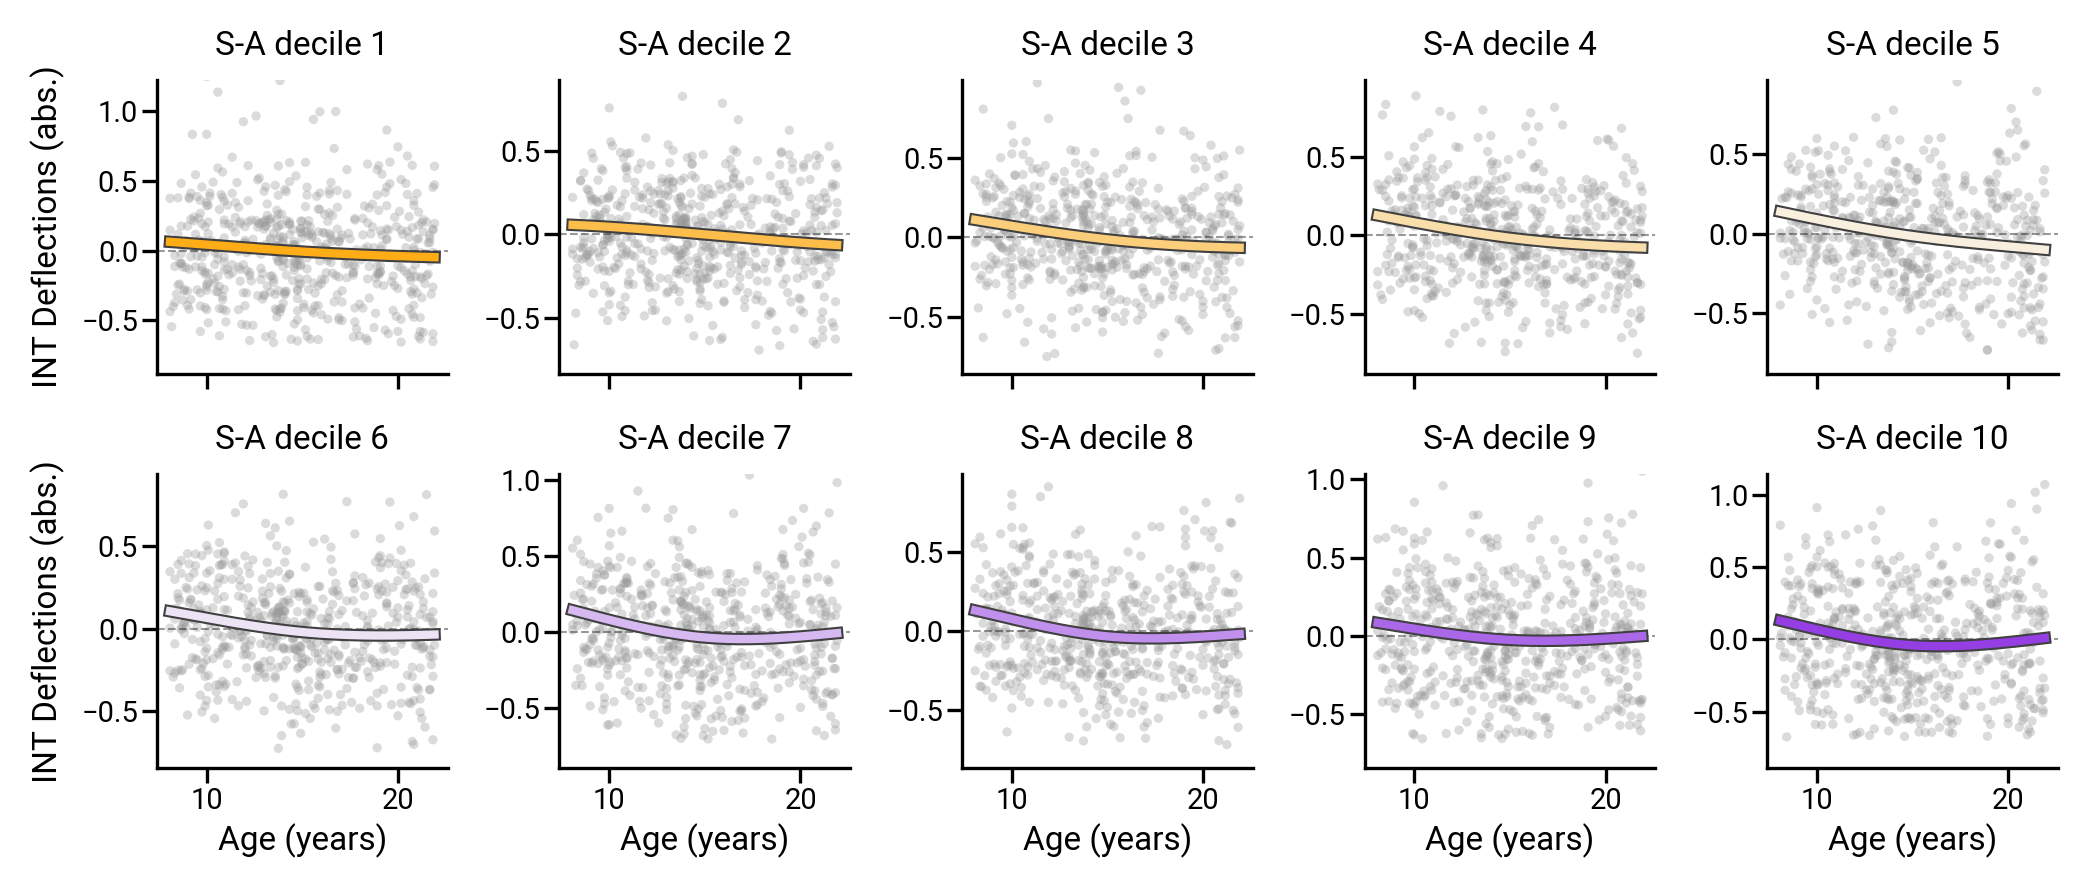

In [12]:
# ── Supplementary: per-decile GAM fit sanity check ──────────────────────────
# Every S-A decile's GAM prediction over the raw decile data it was fit to, centred the same way as the fit.
import matplotlib.patheffects as pe

SUPP_GRID       = (2, 5)      # (rows, cols) of decile panels
SUPP_PANEL_SIZE = (1.4, 1.5)  # size of ONE panel (inches)

_nrow, _ncol = SUPP_GRID
if _nrow * _ncol < n_deciles:
    raise ValueError(f'SUPP_GRID {SUPP_GRID} holds {_nrow * _ncol} panels but there are '
                     f'{n_deciles} deciles to show.')

_rest_dec = data_dict_centiles[rest_scan]
try:
    _task_dec = data_dict_centiles[task_scan]
except (KeyError, TypeError):
    _task_dec = data_dict_centiles[rest_scan]
# Raw decile data per signal, matching what fit_all_panels was handed in the fit cell.
raw_dec  = {'rest': _rest_dec, 'task': _task_dec,
            'deflection': compute_deflections(_rest_dec, _task_dec, absolute=absolute)}[signal_type]
age_subj = df_behavior['age'].values
pred_dec = results_dec[signal_type]['pred']        # (n_deciles, n_grid); demeaned iff demean

fig, axes = plt.subplots(_nrow, _ncol, dpi=300, sharex=True, squeeze=False,
                         figsize=(SUPP_PANEL_SIZE[0] * _ncol, SUPP_PANEL_SIZE[1] * _nrow))
for j in range(_nrow * _ncol):
    ax = axes.ravel()[j]
    if j >= n_deciles:                    # spare cells when the grid is larger than n_deciles
        ax.set_visible(False)
        continue
    y_raw = raw_dec[:, j].astype(float)
    if demean:
        y_raw = y_raw - np.nanmean(y_raw)                    # demean to match the fitted curve
    ax.scatter(age_subj, y_raw, s=5, color='0.6', alpha=0.35, edgecolors='none', zorder=1)
    # Curve coloured by S-A decile (series_colors), with a dark outline via path_effects so the
    # near-white mid-deciles stay visible against the white background.
    ax.plot(age_grid, pred_dec[j], color=series_colors[j], lw=2.0, zorder=3,
            path_effects=[pe.Stroke(linewidth=3.0, foreground='0.25'), pe.Normal()])
    if demean:
        ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4, zorder=2)   # only meaningful when centred
    # Per-panel, outlier-robust limits, because this checks each curve against its own data.
    lo, hi = np.nanpercentile(y_raw, [1, 99])
    ax.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))
    ax.set_title(f'S-A decile {j + 1}', fontsize=8)
    ax.tick_params(labelsize=7, pad=1)
    ax.spines[['top', 'right']].set_visible(False)
    if j // _ncol == _nrow - 1:           # x label on the bottom row only (sharex hides the rest)
        ax.set_xlabel('Age (years)', fontsize=8, labelpad=2)
    if j % _ncol == 0:                    # y label on the leftmost column of each row
        ax.set_ylabel(_signal_labels[signal_type], fontsize=8)
# fig.suptitle(f'Per-decile GAM fit ({signal_type}; {fit_recipe}, n_splines={n_splines}, '
#              f'absolute={absolute}, demean={demean})', fontsize=8, y=1.00)

fig.tight_layout()
_path = save_panel(fig, fig_dir,
                   f'fig3_supp_decile_fits_{task_scan}_{signal_type}{variant_tag}')
print(f'{n_deciles} deciles on a {_nrow}x{_ncol} grid -> {os.path.basename(_path)}.{{png,svg}}')
plt.show()

## Figure 3 — supplement: per-stage net change on the S-A axis

In [13]:
# ── Supplementary: annualized per-stage net change vs the S-A axis (regional + per-decile) ──────
# Annualized stage net change per region, from one bootstrap shared by both stages and one cached S-A
# surrogate set, read entirely from save_dict.
STAGE_METRICS  = {1: 'early_net_annual', 2: 'late_net_annual'}   # stage -> src.gams metric name
STAGE_DECILES  = 10
STAGE_SYM      = 'rho' if SA_CORR_METHOD == 'spearman' else 'r'
STAGE_UNIT     = signal_units(absolute)[signal_type]   # Δ units, from the same dict fig4 labels with
_stage_corr_fn = sp.stats.spearmanr if SA_CORR_METHOD == 'spearman' else sp.stats.pearsonr

# Refuse a tSNR-masked fit, whose columns would no longer match the axis or the surface.
_stage_pred = save_dict[f'{signal_type}_pred']
if save_dict.get('region_mask_applied', False):
    raise ValueError(f'{os.path.basename(gam_cache_file)} was built with apply_tsnr_mask on; the '
                     'stage panels need the full parcellation. Re-run the GAM cell with '
                     'apply_tsnr_mask = False.')
require_full_parcellation(_stage_pred.shape[0], n_regions, os.path.basename(gam_cache_file),
                          'Re-run the GAM cell with apply_tsnr_mask = False.')

# One uncached subject bootstrap at N_BOOT, frozen to the cached fit's settings so the refits reproduce it.
_stage_beh  = save_dict['df_behavior']
_stage_nuis = build_nuisance(_stage_beh, save_dict['rest_reg'], dataset)
_stage_boot = bootstrap_metric_sa_corr(
    save_dict[f'{signal_type}_reg'], _stage_beh['age'].values, age_grid, sa_axis_reg,
    metrics=tuple(STAGE_METRICS.values()), method=SA_CORR_METHOD,
    inflection=float(save_dict['inflection_age']),
    n_splines=save_dict.get('n_splines', n_splines), lam=save_dict[f'{signal_type}_lams'],
    demean=demean, nuisance=_stage_nuis, n_boot=N_BOOT,
    random_state=save_dict['boot_seed'], n_jobs=N_JOBS, verbose=True)

stage_axis_surr = generate_surrogates(sa_axis_reg, name='SA_Axis', n_regions=n_regions,
                                      n_perms=N_PERMS, distance_matrix=distance_matrix,
                                      hemi=hemi_labels, cache_dir=cache_dir, seed=0)

# Per stage: the map, its S-A correlation with bootstrap CI and BrainSMASH p, and decile means, split at the
# shared deflection boundary.
stage_res = {}
for stage, metric in STAGE_METRICS.items():
    _map = sa_metric_map(metric, _stage_pred, age_grid, inflection=float(save_dict['inflection_age']))
    _f   = np.isfinite(_map) & np.isfinite(sa_axis_reg)
    stage_res[stage] = {
        'metric': metric,
        'label':  f'Annualized stage-{stage} net change (Δ{STAGE_UNIT} / yr)',
        'map':    _map,
        'r':      _stage_corr_fn(_map[_f], sa_axis_reg[_f]).statistic,
        'ci':     tuple(np.nanpercentile(_stage_boot[f'r|{metric}'], [2.5, 97.5])),
        'null':   corr_with_null(_map, sa_axis_reg, stage_axis_surr, method=SA_CORR_METHOD),
        # Decile means are tested against zero by the bootstrap, which is not a spatial-enrichment null.
        'dec':    sa_decile_change(_map, _stage_boot[f'map|{metric}'], sa_axis_reg,
                                   n_deciles=STAGE_DECILES),
    }

for stage, res in sorted(stage_res.items()):
    dec = res['dec']
    print(f"{res['label']} vs S-A axis ({SA_CORR_METHOD}); n_boot={N_BOOT}, "
          f'{N_PERMS} BrainSMASH surrogates of the S-A axis:')
    print(f"  regional: {STAGE_SYM}={res['r']:+.3f}  boot95%=[{res['ci'][0]:+.3f},{res['ci'][1]:+.3f}]  "
          f"p_smash={res['null']['p_smash']:.4f}")
    print(f'  per-decile mean (Δ/yr), bootstrap CI + p vs 0  (1=sensorimotor -> {STAGE_DECILES}=association):')
    for i in range(STAGE_DECILES):
        print(f"    decile {dec['decile'][i]:2d} (n={dec['n'][i]:3d}): {dec['mean'][i]:+.4f} "
              f"[{dec['ci_lo'][i]:+.4f}, {dec['ci_hi'][i]:+.4f}]  p={dec['p_boot'][i]:.3f}"
              + (' *' if dec['sig'][i] else ''))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 128 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:    7.4s
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:    7.5s
[Parallel(n_jobs=-1)]: Done  57 tasks      | elapsed:    7.6s
[Parallel(n_jobs=-1)]: Done  82 tasks      | elapsed:    7.6s
[Parallel(n_jobs=-1)]: Done 109 tasks      | elapsed:    7.8s
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:   11.0s
[Parallel(n_jobs=-1)]: Done 165 tasks      | elapsed:   11.2s
[Parallel(n_jobs=-1)]: Done 194 tasks      | elapsed:   11.3s
[Parallel(n_jobs=-1)]: Done 225 tasks      | elapsed:   11.5s
[Parallel(n_jobs=-1)]: Done 256 tasks      | elapsed:   12.3s
[Parallel(n_jobs=-1)]: Done 289 tasks      | elapsed:   14.7s
[Parallel(n_jobs=-1)]: Done 322 tasks      | elapsed:   14.9s
[Parallel(n_jobs=-1)]: Done 357 tasks      | elapsed:   15.2s
[Parallel(n_jobs=-1)]: Done 392 tasks      | elapsed:   18.0s
[Parallel(n_jobs=-1)]: Done 429 tasks      | elapsed: 

Annualized stage-1 net change (Δ|ΔINT| / yr) vs S-A axis (pearson); n_boot=5000, 10000 BrainSMASH surrogates of the S-A axis:
  regional: r=-0.065  boot95%=[-0.205,+0.131]  p_smash=0.4550
  per-decile mean (Δ/yr), bootstrap CI + p vs 0  (1=sensorimotor -> 10=association):
    decile  1 (n= 40): -0.0090 [-0.0170, -0.0028]  p=0.006 *
    decile  2 (n= 40): -0.0056 [-0.0110, -0.0012]  p=0.012 *
    decile  3 (n= 40): -0.0123 [-0.0183, -0.0071]  p=0.000 *
    decile  4 (n= 40): -0.0118 [-0.0179, -0.0064]  p=0.000 *
    decile  5 (n= 40): -0.0127 [-0.0186, -0.0077]  p=0.000 *
    decile  6 (n= 40): -0.0103 [-0.0152, -0.0054]  p=0.000 *
    decile  7 (n= 40): -0.0127 [-0.0181, -0.0071]  p=0.000 *
    decile  8 (n= 40): -0.0144 [-0.0195, -0.0098]  p=0.000 *
    decile  9 (n= 40): -0.0057 [-0.0121, +0.0003]  p=0.061
    decile 10 (n= 40): -0.0139 [-0.0207, -0.0071]  p=0.000 *
Annualized stage-2 net change (Δ|ΔINT| / yr) vs S-A axis (pearson); n_boot=5000, 10000 BrainSMASH surrogates of the S-A

stage 1: vmax=0.034 -> fig3_supp_stage1_map_tfMRICARITPA_deflection_abs_demean_restlen-CARIT.{png,svg}


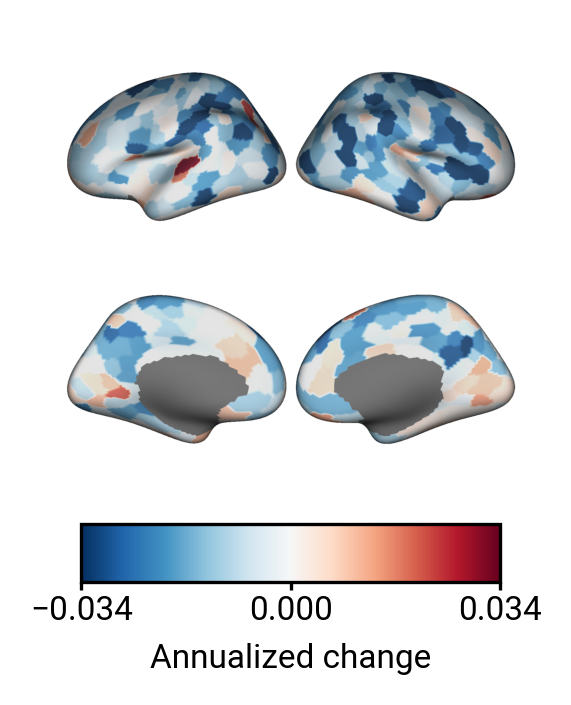

stage 2: vmax=0.023 -> fig3_supp_stage2_map_tfMRICARITPA_deflection_abs_demean_restlen-CARIT.{png,svg}


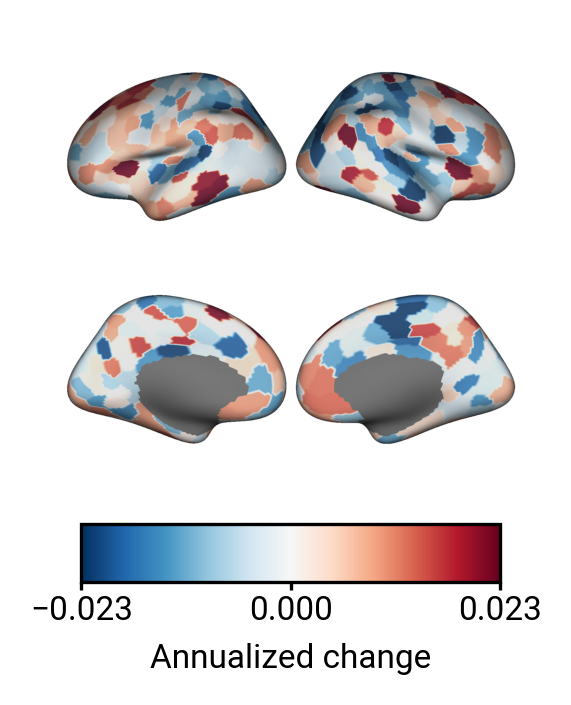

In [14]:
# ── Supplementary panel set 1: per-stage net-change surface maps (one figure per stage) ─────────
# STAGE_SURF_SHARE_SCALES puts both stages on one colour scale (True) or gives each its own 95th-percentile limit (False).
STAGE_SURF_FIGSIZE      = (2.25, 2.5)     # per-stage figure size (inches)
STAGE_SURF_SHARE_SCALES = False

_maps_all = np.concatenate([stage_res[s]['map'] for s in stage_res])

for stage, res in sorted(stage_res.items()):
    vmax = np.round(np.nanpercentile(np.abs(_maps_all if STAGE_SURF_SHARE_SCALES else res['map']), 95), 3)

    fig = plt.figure(figsize=STAGE_SURF_FIGSIZE, dpi=300)
    plot_brain_surface_data_single(res['map'], fig, GridSpec(1, 1, figure=fig)[0, 0],
                                   parcellation=f'schaefer_{n_regions}-7', cmap='RdBu_r',
                                   vmin=-vmax, vmax=vmax, symmetric_cbar=True,
                                   cbar_label='Annualized change', fontsize=8)
    _path = save_panel(fig, fig_dir,
                       f'fig3_supp_stage{stage}_map_{task_scan}_{signal_type}{variant_tag}')
    print(f'stage {stage}: vmax={vmax:.4g} -> {os.path.basename(_path)}.{{png,svg}}')
    plt.show()

stage 1: r=-0.065, p_smash=0.4550 -> fig3_supp_stage1_sa_tfMRICARITPA_deflection_abs_demean_restlen-CARIT.{png,svg}


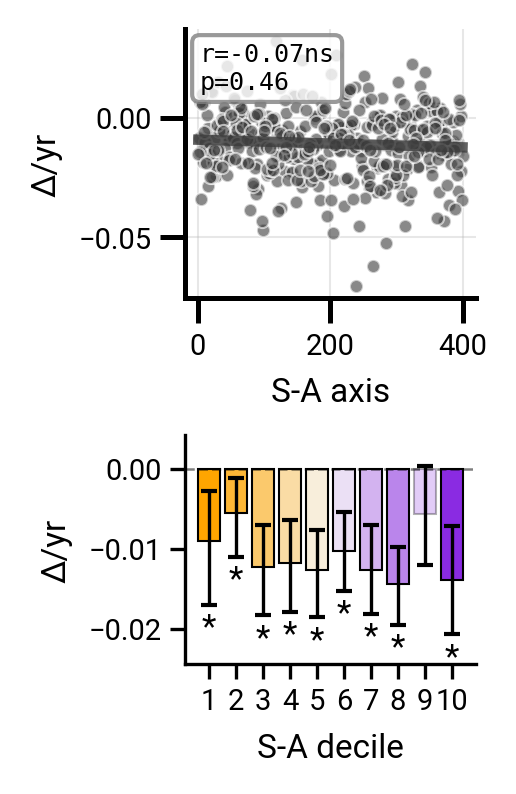

stage 2: r=+0.335, p_smash=0.0000 -> fig3_supp_stage2_sa_tfMRICARITPA_deflection_abs_demean_restlen-CARIT.{png,svg}


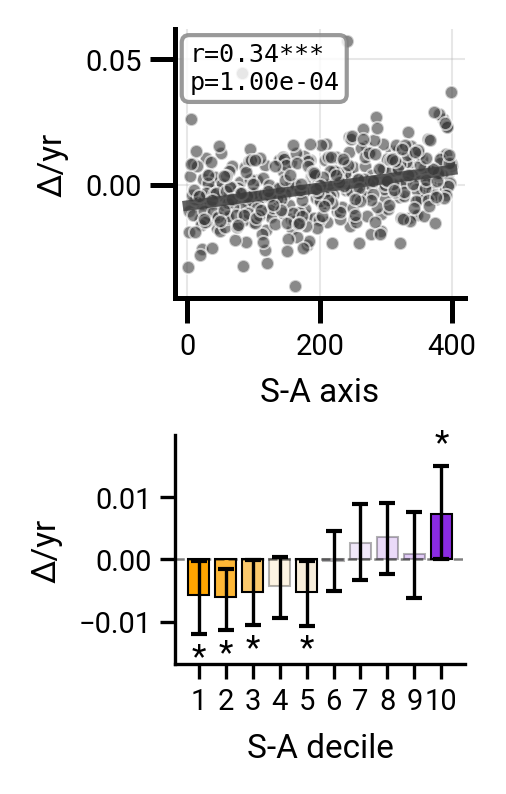

In [15]:
# ── Supplementary panel set 2: S-A statistics per stage (2×1: regional scatter over deciles) ────
# Regional net change against the S-A axis (top, spatial-null p) and decile means with bootstrap CIs (bottom,
# starred where the CI excludes 0).
STAGE_SA_FIGSIZE      = (1.25, 2.75)    # per-stage figure size (inches)
STAGE_SA_SHARE_SCALES = False           # common scatter / decile y-ranges across stages

_all_map = np.concatenate([stage_res[s]['map'] for s in stage_res])
_sc_lo, _sc_hi = np.nanmin(_all_map), np.nanmax(_all_map)
_dec_lo = min(np.nanmin(stage_res[s]['dec']['ci_lo']) for s in stage_res)
_dec_hi = max(np.nanmax(stage_res[s]['dec']['ci_hi']) for s in stage_res)

for stage, res in sorted(stage_res.items()):
    dec = res['dec']
    fig, (ax, axd) = plt.subplots(2, 1, figsize=STAGE_SA_FIGSIZE, dpi=300,
                                  gridspec_kw={'height_ratios': [1.0, 0.85], 'hspace': 0.55})

    # top: regional scatter vs the S-A axis
    fin = np.isfinite(res['map']) & np.isfinite(sa_axis_reg)
    plot_correlation(pd.Series(sa_axis_reg[fin]), pd.Series(res['map'][fin]), ax, x_label='S-A axis',
                     y_label='Δ/yr', method=SA_CORR_METHOD, show_stats=True, fontsize=8,
                     custom_pvalue=max(res['null']['p_smash'], 1 / N_PERMS))
    if STAGE_SA_SHARE_SCALES:
        ax.set_ylim(_sc_lo - 0.06 * (_sc_hi - _sc_lo), _sc_hi + 0.06 * (_sc_hi - _sc_lo))
    ax.tick_params(labelsize=7, pad=2)

    # bottom: decile means with subject-bootstrap CI. cmap is the sydnor S-A map the decile lines
    # and the S-A colorbar above use, so a decile keeps its colour across the whole figure.
    x, colors = dec['decile'], cmap(np.linspace(0, 1, len(dec['decile'])))
    for i, xi in enumerate(x):
        axd.bar(xi, dec['mean'][i], width=0.8, color=colors[i], edgecolor='k', linewidth=0.5,
                alpha=1.0 if dec['sig'][i] else 0.30, zorder=2)
    axd.errorbar(x, dec['mean'],
                 yerr=np.vstack([dec['mean'] - dec['ci_lo'], dec['ci_hi'] - dec['mean']]),
                 fmt='none', ecolor='k', elinewidth=0.8, capsize=2, zorder=3)
    _pad = 0.04 * (np.nanmax(dec['ci_hi']) - np.nanmin(dec['ci_lo']))
    for i, xi in enumerate(x):
        if dec['sig'][i]:
            up = dec['mean'][i] > 0
            axd.text(xi, dec['ci_hi'][i] + _pad if up else dec['ci_lo'][i] - _pad, '*',
                     ha='center', va='bottom' if up else 'top', fontsize=8)
    axd.axhline(0, color='k', lw=0.6, ls='--', alpha=0.5)
    axd.set_xticks(x)
    axd.set_xlabel('S-A decile', fontsize=8)
    axd.set_ylabel('Δ/yr', fontsize=8)
    axd.tick_params(labelsize=7, pad=2)
    if STAGE_SA_SHARE_SCALES:
        axd.set_ylim(_dec_lo - 0.22 * (_dec_hi - _dec_lo), _dec_hi + 0.22 * (_dec_hi - _dec_lo))
    else:
        axd.margins(y=0.18)

    _path = save_panel(fig, fig_dir,
                       f'fig3_supp_stage{stage}_sa_{task_scan}_{signal_type}{variant_tag}')
    print(f"stage {stage}: {STAGE_SYM}={res['r']:+.3f}, p_smash={res['null']['p_smash']:.4f} "
          f'-> {os.path.basename(_path)}.{{png,svg}}')
    plt.show()

## Behaviour

In [16]:
# ── Behaviour configuration ─────────────────────────────────────────────────────────────────
# FOCUS_BEHAVIOUR depends on task_scan, because the in-scanner carit_* measures exist for CARIT only.
CARIT_BEH = ['carit_nogo_acc', 'carit_dprime', 'carit_omission_rate', 'carit_criterion']
EF_BEH    = ['nih_fluidcogcomp_unadjusted', 'nih_crycogcomp_unadjusted', 'tbx_ls',
             'nih_flanker_ageadjusted', 'nih_dccs_ageadjusted', 'nih_patterncomp_ageadjusted',
             'tbx_vocab_theta', 'tbx_reading_score']
HAS_TASK_ACC = task_scan == 'tfMRICARITPA'
TEST_BEH = (CARIT_BEH if HAS_TASK_ACC else []) + EF_BEH

FOCUS_BEHAVIOUR = 'carit_nogo_acc' if HAS_TASK_ACC else 'tbx_ls'   # any entry of TEST_BEH
AGE_SPLIT       = 15.0        # fig3's deflection stage boundary is ~15 y; a knob, not a fit
# AGE_BASIS partials age out linearly (as fig2 does) or with a 5-column cubic B-spline.
AGE_BASIS = 'linear'          # 'linear' | 'spline'

if FOCUS_BEHAVIOUR not in TEST_BEH:
    raise ValueError(f'FOCUS_BEHAVIOUR {FOCUS_BEHAVIOUR!r} is not available for {task_scan}. '
                     f'Choose one of {TEST_BEH}.')
KIND = 'absolute' if absolute else 'signed'      # follows the GAM figure's deflection definition
print(f'{task_scan}: focus {FOCUS_BEHAVIOUR!r}, {KIND} deflection, split at {AGE_SPLIT:g} y')

tfMRICARITPA: focus 'carit_nogo_acc', absolute deflection, split at 15 y


In [17]:
# ── Inputs: rest and task INTs, behaviour, covariates and S-A surrogates ────────────────────
# rest/task come from the same data_dict_converted the GAM section uses, so subjects, parcels and
# the rest-length variant are identical to the figure above.
rest_beh = data_dict_converted[rest_scan]
task_beh = data_dict_converted[task_scan]
require_full_parcellation(rest_beh.shape[1], n_regions, 'rest INT matrix')

beh = df_behavior.apply(pd.to_numeric, errors='coerce')
if HAS_TASK_ACC:
    beh.loc[beh['carit_perf_exclude'] == True, CARIT_BEH] = np.nan   # published CARIT screen

# Nuisance set from the shared owner, exactly as fig2/fig4 build it: [age, sex, motion, mean rest INT].
_nuisance = build_nuisance(beh, rest_beh, dataset, include_age=True)
age_vals = beh['age'].values
print(f'covariates: age ({AGE_BASIS}) + sex + head motion + mean rest INT')

# The same surrogates panel E uses: generate_surrogates reads the cache when N_PERMS matches, so
# this is a lookup rather than a rebuild.
_dist, _hemi, _cache_dir = null_basis(timescales_processor, dataset, n_regions)
sa_axis_surr = generate_surrogates(sa_axis, name='SA_Axis', n_regions=n_regions, n_perms=N_PERMS,
                                   distance_matrix=_dist, hemi=_hemi, cache_dir=_cache_dir, seed=0)

covariates: age (linear) + sex + head motion + mean rest INT


-> fig3_beh_sa_absolute_tfMRICARITPA_carit_nogo_acc_split15_abs_demean_restlen-CARIT.{png,svg}


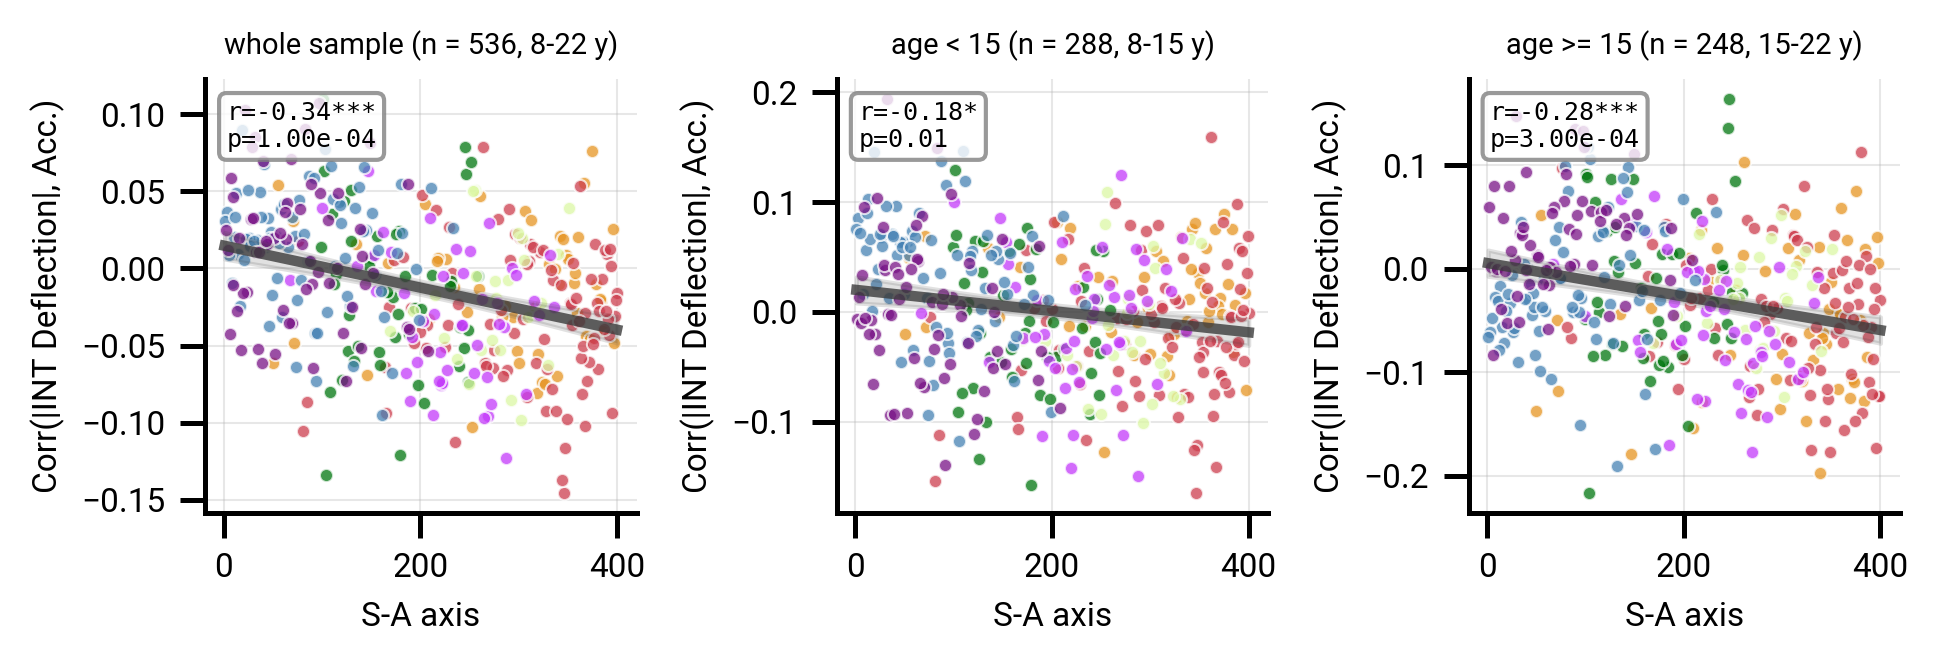

,group,n,n_with_behaviour,age_lo,age_hi,r_map_sa,p_smash,max_abs_r
0,whole sample,552,536,8.0833,21.9167,-0.3384,0.0001,0.1455
1,age < 15,300,288,8.0833,14.9167,-0.1819,0.0103,0.1944
2,age >= 15,252,248,15.0000,21.9167,-0.2786,0.0003,0.2164


In [18]:
# ── The chosen behaviour: whole sample, then early vs later development (1x3) ───────────────
# The association's S-A gradient over everyone (left) and within each age group with age still a covariate
# (middle, right), descriptive rather than an interaction test.
_groups = [('whole sample', np.ones_like(age_vals, dtype=bool)),
           (f'age < {AGE_SPLIT:g}', age_vals < AGE_SPLIT),
           (f'age >= {AGE_SPLIT:g}', age_vals >= AGE_SPLIT)]
_y = beh[FOCUS_BEHAVIOUR].values
if 'acc' in FOCUS_BEHAVIOUR:
    y_label_text = 'Acc.'
else:
    y_label_text = FOCUS_BEHAVIOUR

split_maps, _rows = {}, []
for _label, _m in _groups:
    _a = age_vals[_m]
    _cols = (np.asarray(dmatrix("bs(a, df=5, include_intercept=False) - 1", {"a": _a}))
             if AGE_BASIS == 'spline' else _a[:, None])
    _, _, _r_defl = compute_regional_corrs(rest_beh[_m], task_beh[_m], _y[_m],
                                           covariate=np.column_stack([_cols, _nuisance[_m, 1:]]),
                                           absolute=(KIND == 'absolute'))
    split_maps[_label] = _r_defl
    _rows.append(dict(group=_label, n=int(_m.sum()),
                      n_with_behaviour=int(np.isfinite(_y[_m]).sum()),
                      age_lo=age_vals[_m].min(), age_hi=age_vals[_m].max(),
                      r_map_sa=sp.stats.pearsonr(_r_defl, sa_axis)[0],
                      p_smash=max(corr_with_null(_r_defl, sa_axis, sa_axis_surr)['p_smash'],
                                  1 / N_PERMS),
                      max_abs_r=np.abs(_r_defl).max()))
split_res = pd.DataFrame(_rows)

_all = np.concatenate(list(split_maps.values()))
_pad = 0.05 * (_all.max() - _all.min())
fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.25), dpi=300, sharey=False)
for _ax, (_label, _) in zip(axes, _groups):
    _row = split_res.set_index('group').loc[_label]
    plot_correlation(sa_axis, split_maps[_label], _ax,
                     x_label='S-A axis',
                     y_label=f'Corr(|INT Deflection|, {y_label_text})',
                     custom_pvalue=_row['p_smash'],
                     data_group=yeo_systems, data_group_cmap='yeo7',
                     cbar_label='Yeo Systems',  show_colorbar=False, # show_colorbar=(_ax is axes[-1]),
                     method='pearson', size=10, alpha=0.75, fontsize=8, grid=True)
    # _ax.axhline(0, color='k', lw=0.6, zorder=0)
    # _ax.set_ylim(_all.min() - _pad, _all.max() + _pad)
    _ax.set_title(f"{_label} (n = {int(_row['n_with_behaviour'])}, "
                  f"{_row['age_lo']:.0f}-{_row['age_hi']:.0f} y)", fontsize=7)
# fig.suptitle(f'{FOCUS_BEHAVIOUR} — S-A gradient of the deflection-behaviour association '
            #  f'({KIND} deflection, {task_scan})', fontsize=8)
fig.tight_layout()

_path = save_panel(fig, fig_dir,
                   f'fig3_beh_sa_{KIND}_{task_scan}_{FOCUS_BEHAVIOUR}_split{AGE_SPLIT:g}{variant_tag}',
                   dpi=300)
print(f'-> {os.path.basename(_path)}.{{png,svg}}')
plt.show()

split_res.round(4)